# Step 10 — Microgrid Forecasting & Dispatch Visualizations

This notebook creates graphs from the CSV results already generated by Steps 6–9.

**Before running:** Open this notebook in VS Code from the project root folder (`microgrid_ai`). Make sure the `.venv` Python interpreter is selected and the notebook kernel is set to that environment.

If plotting libraries are missing, run this once in the VS Code terminal:

```powershell
python -m pip install pandas matplotlib numpy
```

Run cells from top to bottom using **Run All** or the play button beside each cell.

> Data note: the NASA-based dataset contains NASA POWER gridded weather estimates. PV and wind generation are modeled from weather, and load is synthetic. These are simulation results, not measurements from a physical microgrid.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Resolve the project folder whether this notebook is in the project root
# or in a subfolder such as notebooks/.
cwd = Path.cwd()
if (cwd / "outputs").exists():
    PROJECT_DIR = cwd
elif (cwd.parent / "outputs").exists():
    PROJECT_DIR = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find the outputs folder. Open this notebook from the microgrid_ai project."
    )

OUTPUT_DIR = PROJECT_DIR / "outputs"
print("Project folder:", PROJECT_DIR)
print("Outputs folder:", OUTPUT_DIR)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


Project folder: c:\Users\yashwanth\OneDrive\Desktop\final year project\microgrid_ai
Outputs folder: c:\Users\yashwanth\OneDrive\Desktop\final year project\microgrid_ai\outputs


In [2]:
# Load the result files generated by Steps 8 and 9
required_files = [
    "hourly_forecast_metrics.csv",
    "hourly_dispatch_summary.csv",
    "synthetic_hourly_forecast_results.csv",
    "nasa_hourly_forecast_results.csv",
]

for filename in required_files:
    path = OUTPUT_DIR / filename
    if not path.exists():
        print(f"NOT FOUND: {filename}")
    else:
        print(f"Found: {filename}")

forecast_metrics_path = OUTPUT_DIR / "hourly_forecast_metrics.csv"
dispatch_summary_path = OUTPUT_DIR / "hourly_dispatch_summary.csv"

if forecast_metrics_path.exists():
    forecast_metrics = pd.read_csv(forecast_metrics_path)
    print("\nForecast metrics columns:", forecast_metrics.columns.tolist())
    display(forecast_metrics.head())

if dispatch_summary_path.exists():
    dispatch_summary = pd.read_csv(dispatch_summary_path)
    print("\nDispatch summary columns:", dispatch_summary.columns.tolist())
    display(dispatch_summary)


Found: hourly_forecast_metrics.csv
Found: hourly_dispatch_summary.csv
Found: synthetic_hourly_forecast_results.csv
Found: nasa_hourly_forecast_results.csv

Forecast metrics columns: ['Dataset', 'Target', 'Model', 'MAE_kW', 'RMSE_kW']


,Dataset,Target,Model,MAE_kW,RMSE_kW
0,Synthetic,PV,Persistence,7.410,11.479
1,Synthetic,PV,Random Forest,0.738,3.448
2,Synthetic,PV,Gradient Boosting,0.932,3.607
3,Synthetic,Wind,Persistence,4.554,6.243
4,Synthetic,Wind,Random Forest,4.687,6.482



Dispatch summary columns: ['Dataset', 'Strategy', 'Unserved Energy (kWh)', 'Diesel Fuel (L)', 'Diesel Energy (kWh)', 'Diesel Starts', 'CO2 Emissions (kg)']


,Dataset,Strategy,Unserved Energy (kWh),Diesel Fuel (L),Diesel Energy (kWh),Diesel Starts,CO2 Emissions (kg)
0,Synthetic,Reactive (No AI),286.418,6666.700,9648.253,18,17866.757
1,Synthetic,AI Forecast,108.438,6992.868,10016.257,19,18740.886
2,Synthetic,Perfect Forecast,53.672,7101.366,10136.257,18,19031.661
3,NASA-based,Reactive (No AI),136.117,7835.836,13602.324,15,21000.039
4,NASA-based,AI Forecast,52.401,8269.828,14082.324,21,22163.138
5,NASA-based,Perfect Forecast,0.000,8242.703,14052.324,15,22090.444


## 1. Forecasting performance — MAE

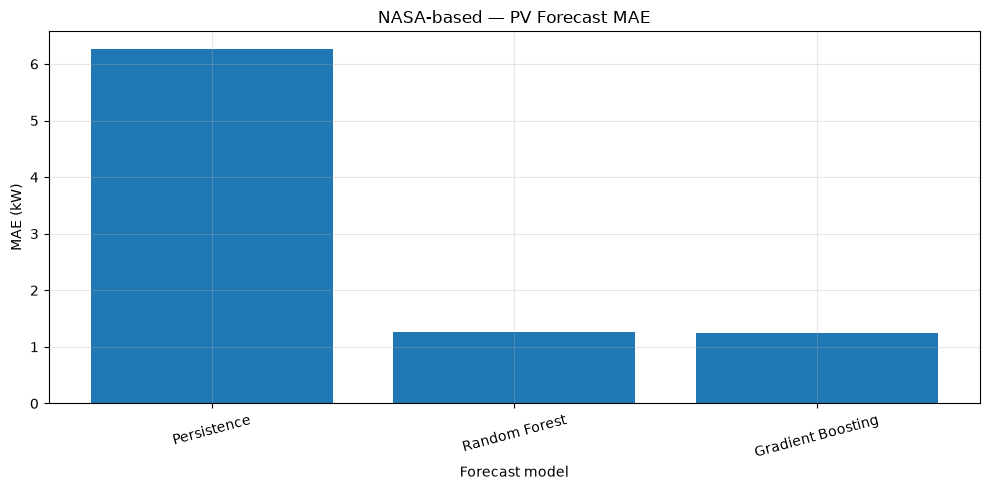

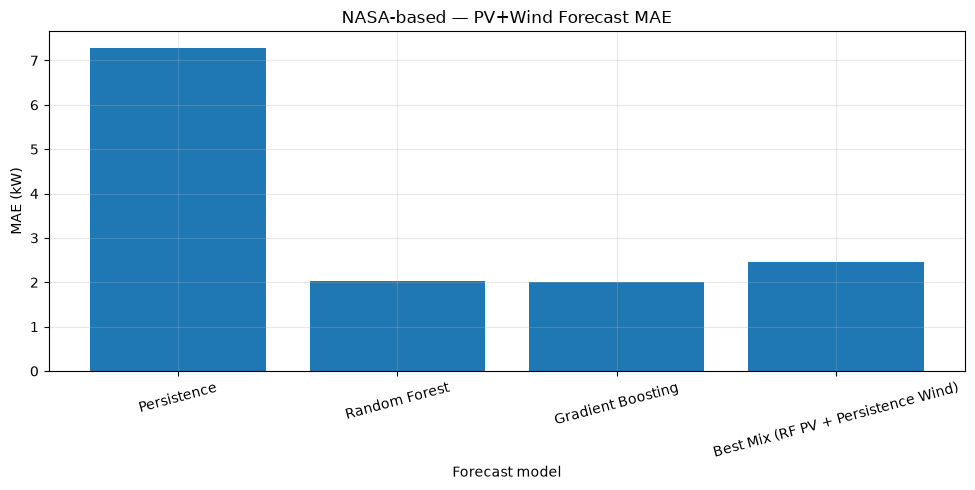

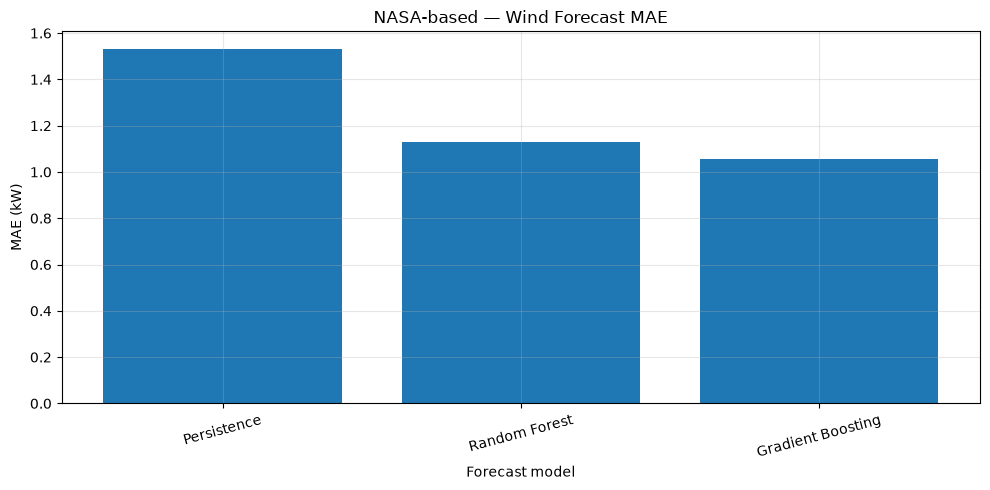

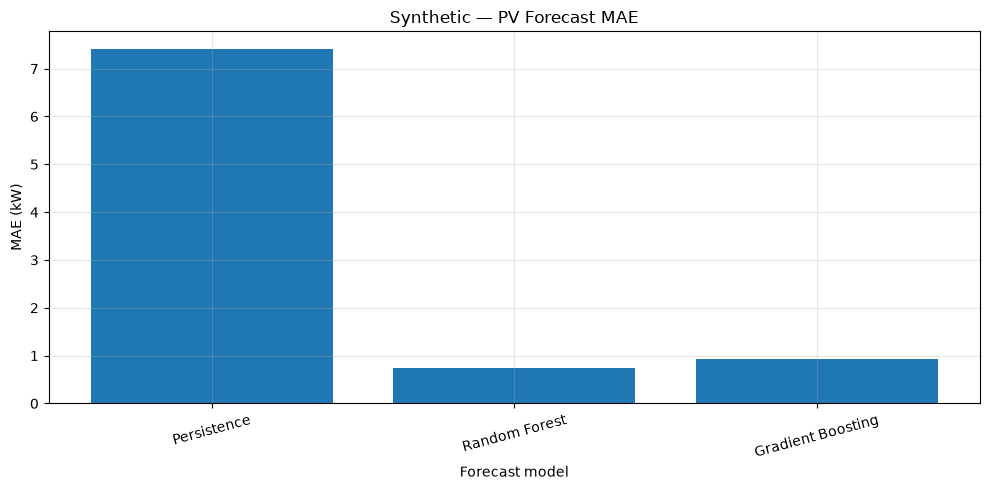

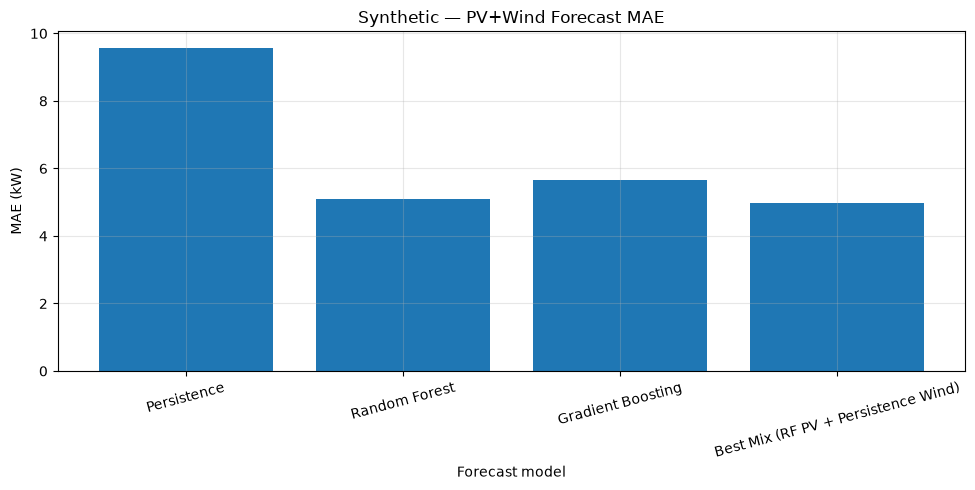

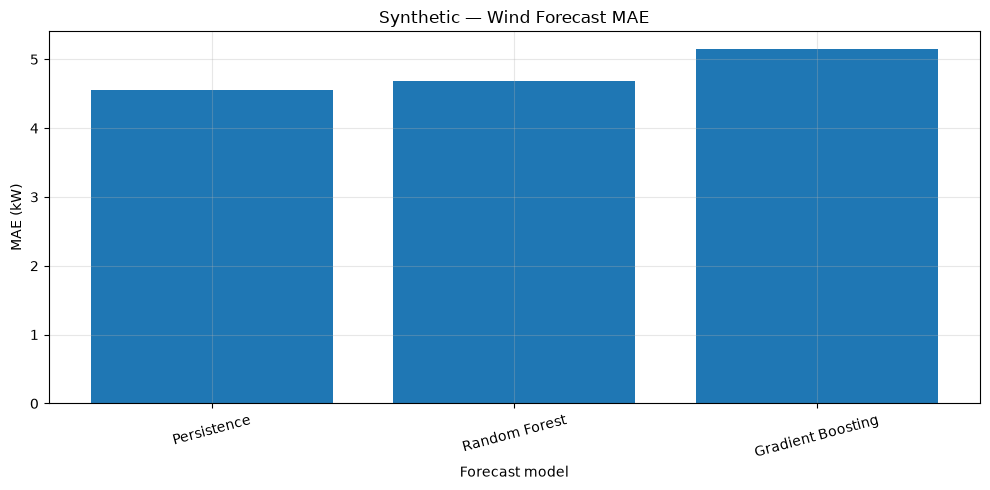

In [3]:
if "forecast_metrics" not in globals():
    raise FileNotFoundError("hourly_forecast_metrics.csv was not found in outputs.")

# The generated file uses Dataset, Target, Model and MAE_kW.
# Normalize column names to make this cell tolerant of small naming differences.
forecast_metrics.columns = [str(c).strip() for c in forecast_metrics.columns]
mae_col = next((c for c in forecast_metrics.columns if c.lower().replace(" ", "_") in ["mae_kw", "mae"]), None)
dataset_col = next((c for c in forecast_metrics.columns if c.lower() == "dataset"), None)
target_col = next((c for c in forecast_metrics.columns if c.lower() == "target"), None)
model_col = next((c for c in forecast_metrics.columns if c.lower() == "model"), None)

if all([mae_col, dataset_col, target_col, model_col]):
    plot_df = forecast_metrics.copy()
    plot_df[mae_col] = pd.to_numeric(plot_df[mae_col], errors="coerce")
    for (dataset, target), group in plot_df.groupby([dataset_col, target_col]):
        plt.figure()
        plt.bar(group[model_col].astype(str), group[mae_col])
        plt.title(f"{dataset} — {target} Forecast MAE")
        plt.ylabel("MAE (kW)")
        plt.xlabel("Forecast model")
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()
else:
    print("Could not identify the expected Dataset / Target / Model / MAE columns.")
    display(forecast_metrics.head())


## 2. Forecasting performance — RMSE

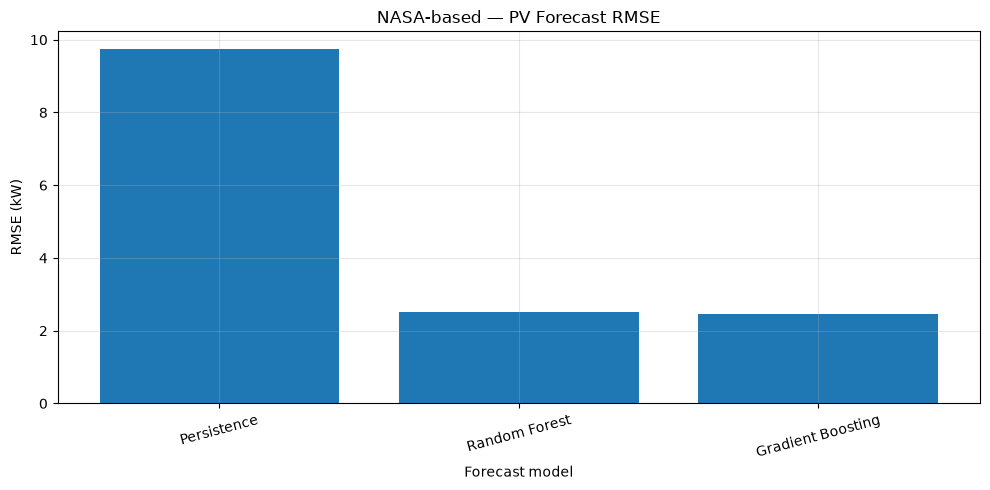

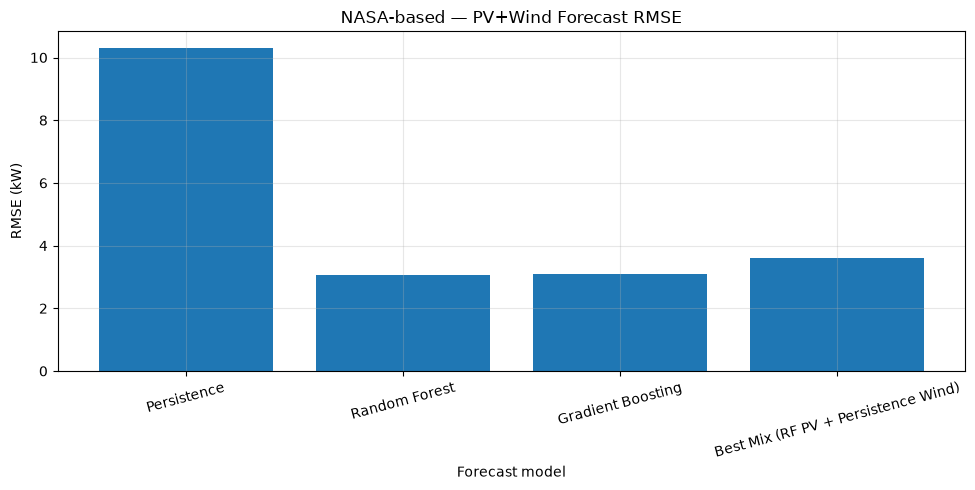

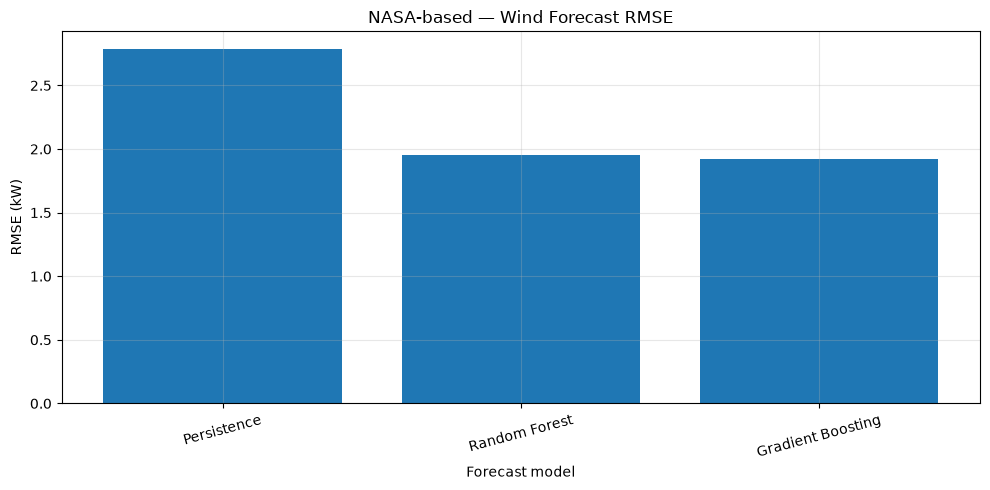

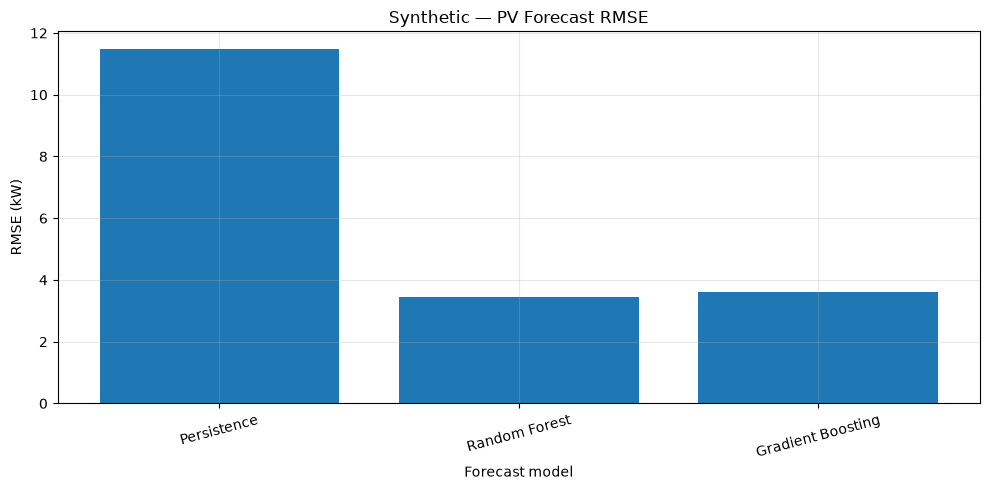

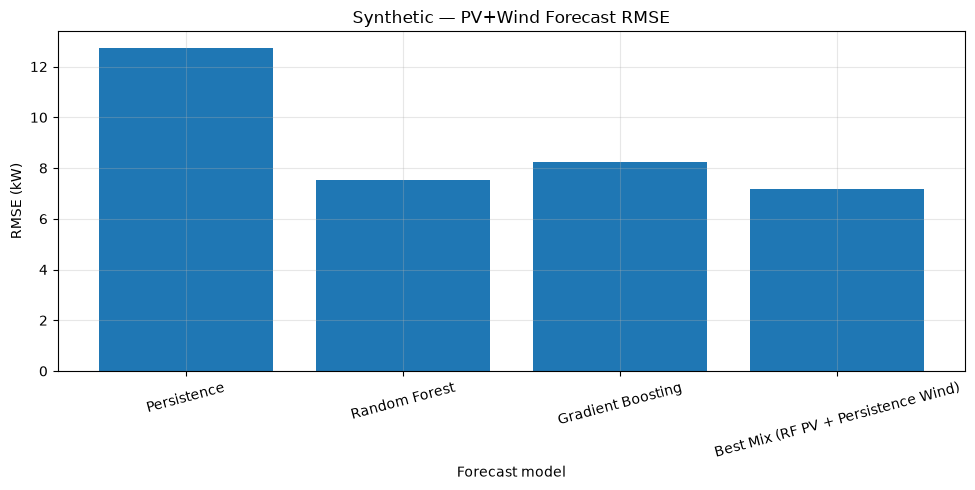

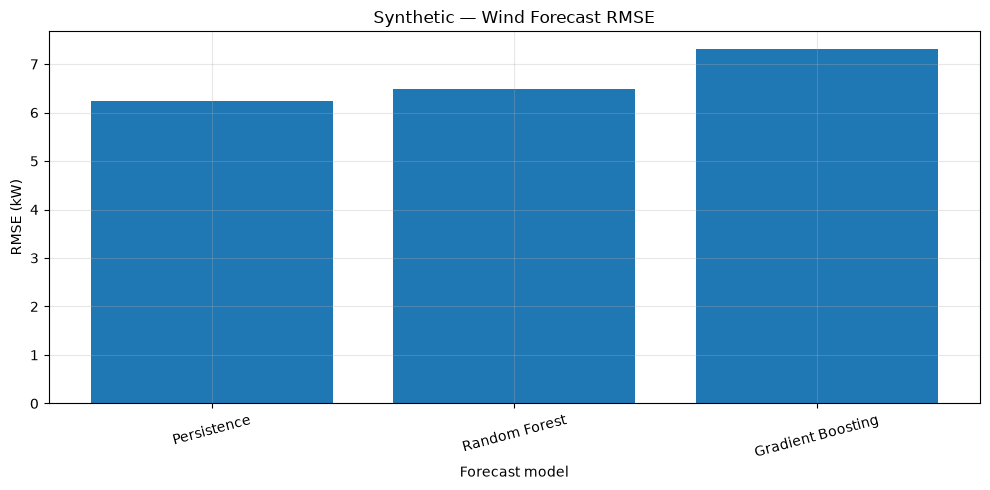

In [4]:
rmse_col = next((c for c in forecast_metrics.columns if c.lower().replace(" ", "_") in ["rmse_kw", "rmse"]), None)

if all([rmse_col, dataset_col, target_col, model_col]):
    forecast_metrics[rmse_col] = pd.to_numeric(forecast_metrics[rmse_col], errors="coerce")
    for (dataset, target), group in forecast_metrics.groupby([dataset_col, target_col]):
        plt.figure()
        plt.bar(group[model_col].astype(str), group[rmse_col])
        plt.title(f"{dataset} — {target} Forecast RMSE")
        plt.ylabel("RMSE (kW)")
        plt.xlabel("Forecast model")
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()
else:
    print("RMSE column was not found in the forecast metrics file.")


## 3. Dispatch comparison — unserved energy

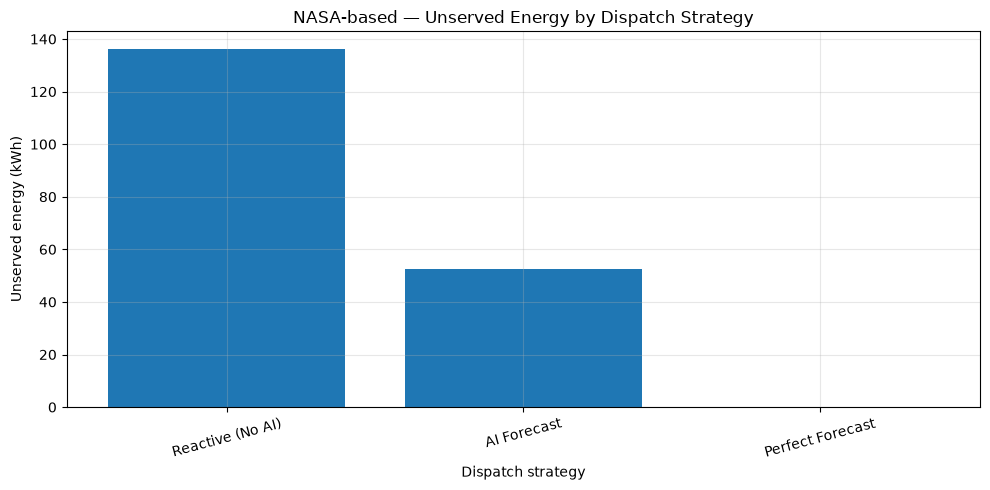

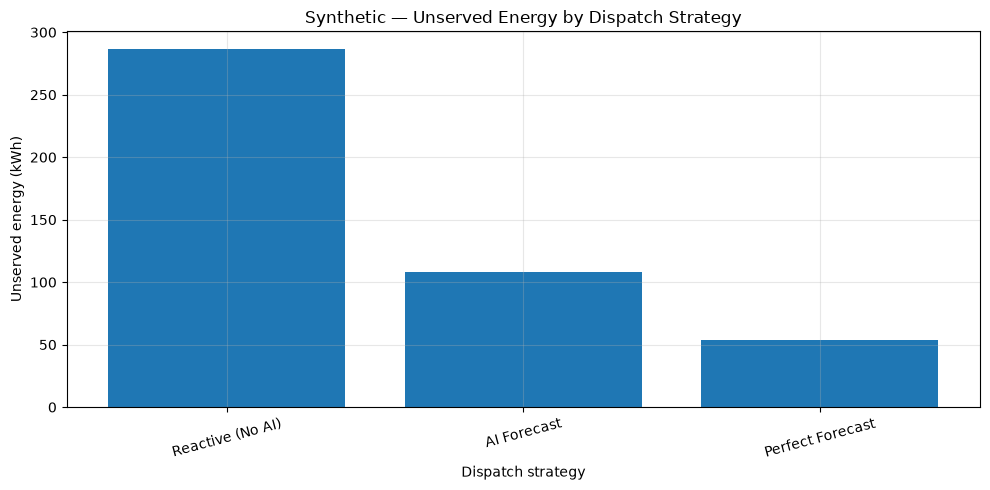

In [5]:
if "dispatch_summary" not in globals():
    raise FileNotFoundError("hourly_dispatch_summary.csv was not found in outputs.")

# Match the printed Step 9 table's column names.
dispatch_summary.columns = [str(c).strip() for c in dispatch_summary.columns]
unserved_col = next((c for c in dispatch_summary.columns if "unserved" in c.lower()), None)
fuel_col = next((c for c in dispatch_summary.columns if "fuel" in c.lower()), None)
co2_col = next((c for c in dispatch_summary.columns if "co2" in c.lower()), None)
strategy_col = next((c for c in dispatch_summary.columns if "strategy" in c.lower()), None)
dispatch_dataset_col = next((c for c in dispatch_summary.columns if c.lower() == "dataset"), None)

if all([unserved_col, strategy_col, dispatch_dataset_col]):
    for dataset, group in dispatch_summary.groupby(dispatch_dataset_col):
        plt.figure()
        plt.bar(group[strategy_col].astype(str), pd.to_numeric(group[unserved_col], errors="coerce"))
        plt.title(f"{dataset} — Unserved Energy by Dispatch Strategy")
        plt.ylabel("Unserved energy (kWh)")
        plt.xlabel("Dispatch strategy")
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()
else:
    print("Could not identify dispatch summary columns.")
    display(dispatch_summary.head())


## 4. Dispatch comparison — diesel fuel consumption

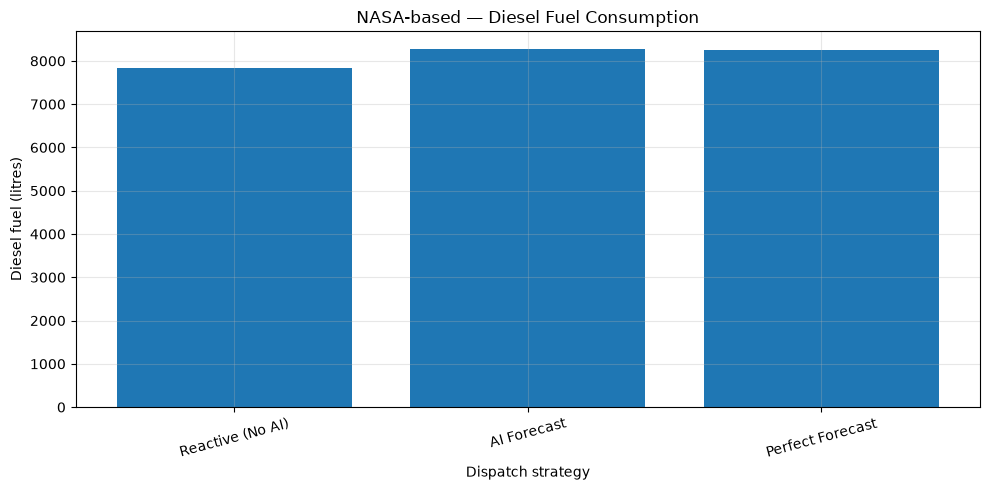

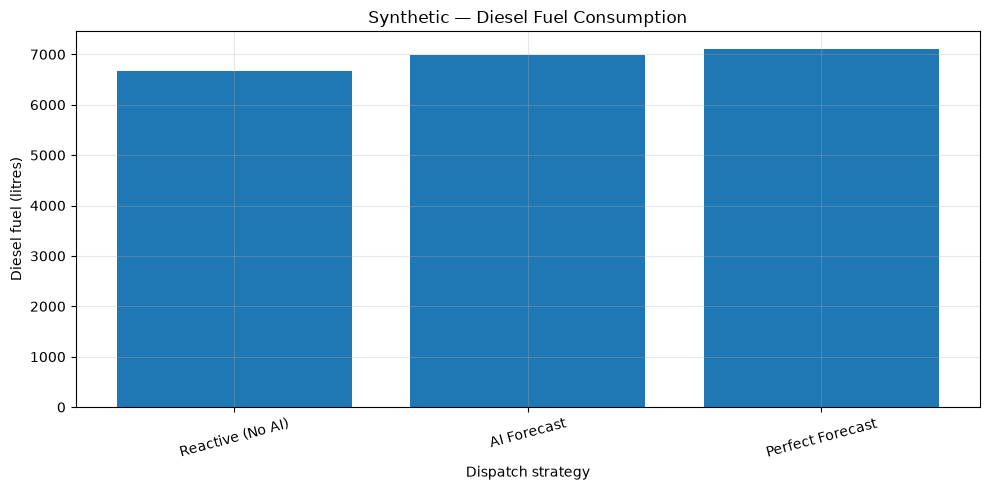

In [6]:
if all([fuel_col, strategy_col, dispatch_dataset_col]):
    for dataset, group in dispatch_summary.groupby(dispatch_dataset_col):
        plt.figure()
        plt.bar(group[strategy_col].astype(str), pd.to_numeric(group[fuel_col], errors="coerce"))
        plt.title(f"{dataset} — Diesel Fuel Consumption")
        plt.ylabel("Diesel fuel (litres)")
        plt.xlabel("Dispatch strategy")
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()
else:
    print("Fuel / strategy / dataset columns were not identified.")


## 5. Dispatch comparison — CO₂ emissions

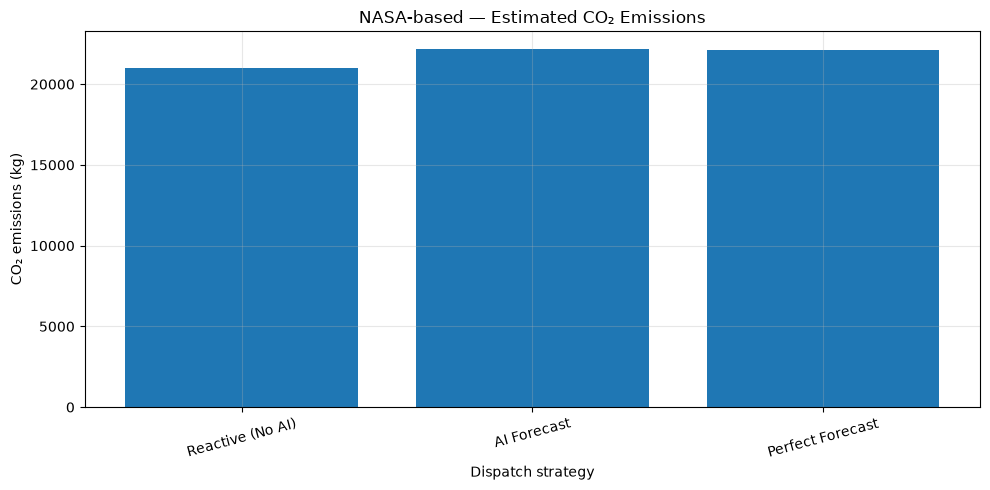

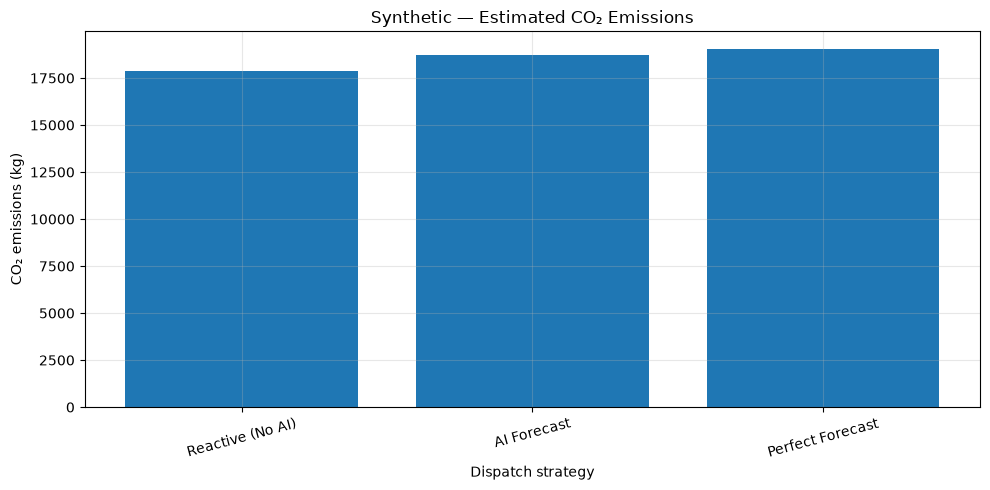

In [7]:
if all([co2_col, strategy_col, dispatch_dataset_col]):
    for dataset, group in dispatch_summary.groupby(dispatch_dataset_col):
        plt.figure()
        plt.bar(group[strategy_col].astype(str), pd.to_numeric(group[co2_col], errors="coerce"))
        plt.title(f"{dataset} — Estimated CO₂ Emissions")
        plt.ylabel("CO₂ emissions (kg)")
        plt.xlabel("Dispatch strategy")
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()
else:
    print("CO2 / strategy / dataset columns were not identified.")


## 6. Actual vs predicted renewable generation (if forecast detail columns are available)

This cell inspects the two forecast-result CSVs and tries to identify timestamp, actual-value, and prediction columns. If your Step 8 files contain only summary metrics, this cell will show their columns instead; the MAE/RMSE graphs above will still work.



Synthetic:
Columns: ['time', 'load_kw', 'actual_renewable_kw', 'persistence_kw', 'rf_kw', 'gb_kw', 'mix_kw']


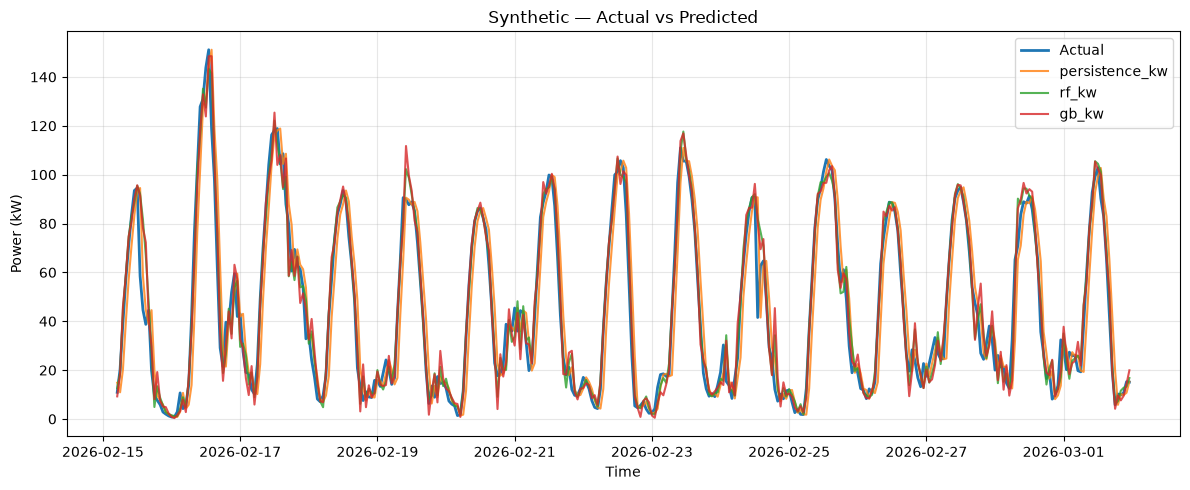


NASA-based:
Columns: ['time', 'load_kw', 'actual_renewable_kw', 'persistence_kw', 'rf_kw', 'gb_kw', 'mix_kw']


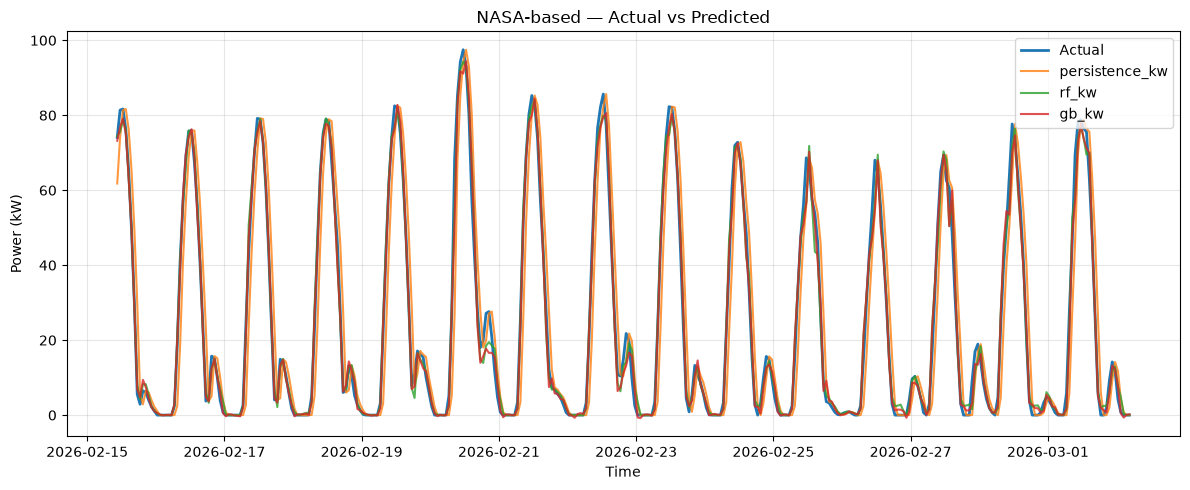

In [8]:
def find_column(df, candidates):
    lower_map = {str(c).lower().strip(): c for c in df.columns}
    for candidate in candidates:
        if candidate in lower_map:
            return lower_map[candidate]
    # fallback: partial match
    for c in df.columns:
        cl = str(c).lower().strip()
        if any(candidate in cl for candidate in candidates):
            return c
    return None

forecast_files = {
    "Synthetic": OUTPUT_DIR / "synthetic_hourly_forecast_results.csv",
    "NASA-based": OUTPUT_DIR / "nasa_hourly_forecast_results.csv",
}

for label, path in forecast_files.items():
    print(f"\n{label}:")
    if not path.exists():
        print("File not found:", path.name)
        continue

    df = pd.read_csv(path)
    print("Columns:", df.columns.tolist())

    time_col = find_column(df, ["timestamp", "datetime", "date_time", "time"])
    actual_col = find_column(df, ["actual_kw", "actual", "y_true", "observed_kw", "measured_kw"])
    prediction_cols = [
        c for c in df.columns
        if any(token in str(c).lower() for token in ["persistence", "rf_kw", "gb_kw", "predicted", "forecast"])
        and c != actual_col
    ]

    if time_col and actual_col and prediction_cols:
        df[time_col] = pd.to_datetime(df[time_col], errors="coerce")
        df = df.sort_values(time_col)
        plt.figure(figsize=(12, 5))
        plt.plot(df[time_col], df[actual_col], label="Actual", linewidth=2)
        for col in prediction_cols[:4]:
            plt.plot(df[time_col], df[col], label=str(col), alpha=0.8)
        plt.title(f"{label} — Actual vs Predicted")
        plt.xlabel("Time")
        plt.ylabel("Power (kW)")
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("This file does not appear to contain time-series actual/prediction columns.")
        display(df.head())


## 7. Diesel generator operation over time (if available)


Synthetic dispatch details:
Columns: ['time', 'strategy', 'load_kw', 'renewable_kw', 'forecast_kw', 'diesel_output_kw', 'unserved_kw', 'generator_on']


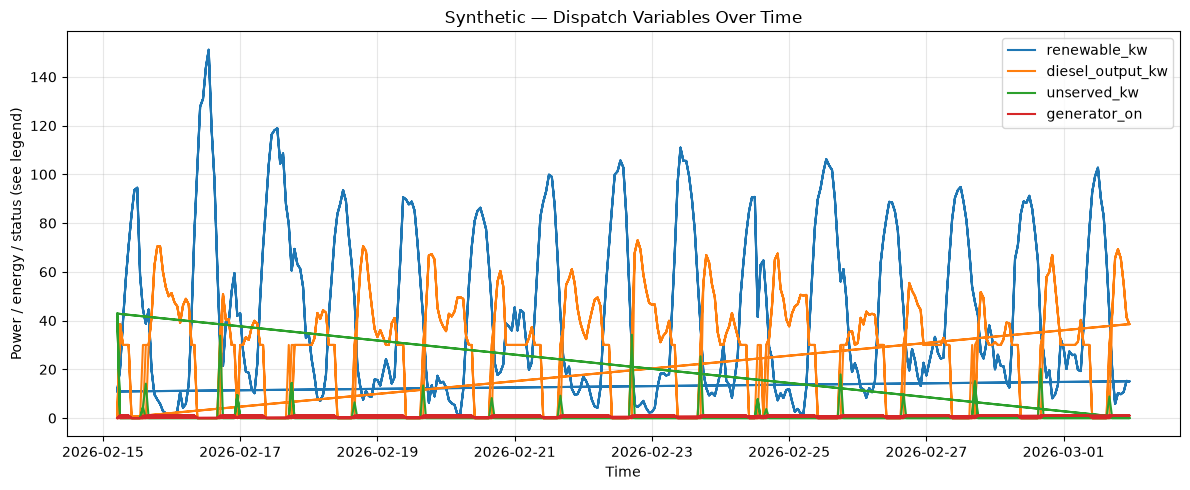


NASA-based dispatch details:
Columns: ['time', 'strategy', 'load_kw', 'renewable_kw', 'forecast_kw', 'diesel_output_kw', 'unserved_kw', 'generator_on']


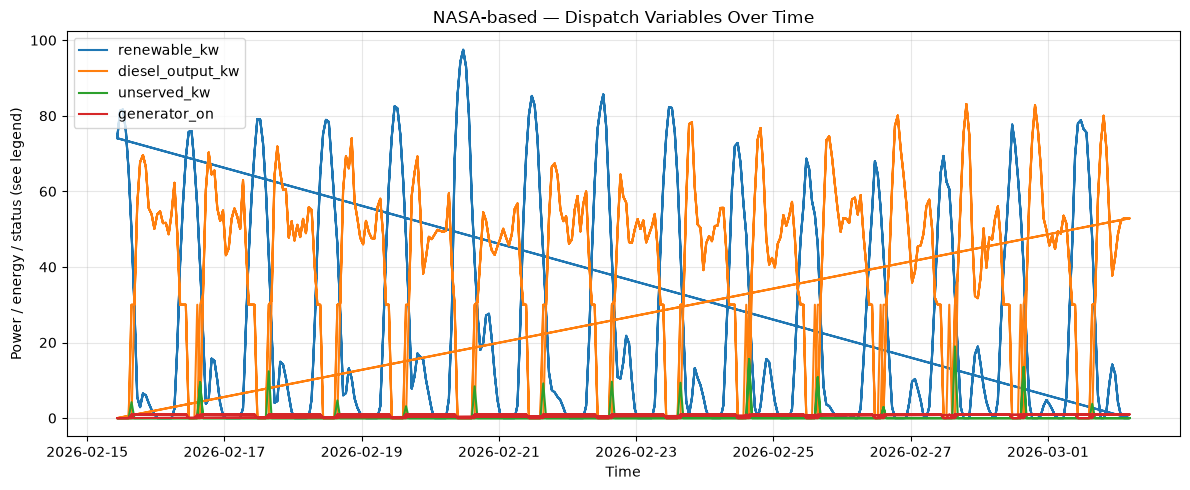

In [9]:
detail_files = {
    "Synthetic": OUTPUT_DIR / "hourly_dispatch_details_synthetic.csv",
    "NASA-based": OUTPUT_DIR / "hourly_dispatch_details_nasa_based.csv",
}

for label, path in detail_files.items():
    print(f"\n{label} dispatch details:")
    if not path.exists():
        print("File not found:", path.name)
        continue

    df = pd.read_csv(path)
    print("Columns:", df.columns.tolist())
    time_col = find_column(df, ["timestamp", "datetime", "date_time", "time", "hour"])
    numeric_cols = df.select_dtypes(include="number").columns.tolist()

    # Prefer generator output / diesel power / generator status-like numeric fields.
    preferred = [
        c for c in numeric_cols
        if any(term in str(c).lower() for term in ["diesel", "generator", "gen_kw", "unserved", "renewable"])
    ]

    if time_col and preferred:
        x = pd.to_datetime(df[time_col], errors="coerce")
        plt.figure(figsize=(12, 5))
        for col in preferred[:5]:
            plt.plot(x, df[col], label=str(col))
        plt.title(f"{label} — Dispatch Variables Over Time")
        plt.xlabel("Time")
        plt.ylabel("Power / energy / status (see legend)")
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("No recognizable time + dispatch numeric columns found. Preview:")
        display(df.head())


## 8. Save a copy of the key result tables

The charts display inside VS Code. The CSV files remain unchanged in `outputs/`. This final cell prints the key tables for convenient review.


In [10]:
print("FORECAST METRICS")
display(forecast_metrics)

print("\nDISPATCH SUMMARY")
display(dispatch_summary)


FORECAST METRICS


,Dataset,Target,Model,MAE_kW,RMSE_kW
0,Synthetic,PV,Persistence,7.410,11.479
1,Synthetic,PV,Random Forest,0.738,3.448
2,Synthetic,PV,Gradient Boosting,0.932,3.607
3,Synthetic,Wind,Persistence,4.554,6.243
4,Synthetic,Wind,Random Forest,4.687,6.482
5,Synthetic,Wind,Gradient Boosting,5.149,7.310
6,Synthetic,PV+Wind,Persistence,9.583,12.753
7,Synthetic,PV+Wind,Random Forest,5.105,7.511
8,Synthetic,PV+Wind,Gradient Boosting,5.646,8.235
9,Synthetic,PV+Wind,Best Mix (RF PV + Persistence Wind),4.967,7.193



DISPATCH SUMMARY


,Dataset,Strategy,Unserved Energy (kWh),Diesel Fuel (L),Diesel Energy (kWh),Diesel Starts,CO2 Emissions (kg)
0,Synthetic,Reactive (No AI),286.418,6666.700,9648.253,18,17866.757
1,Synthetic,AI Forecast,108.438,6992.868,10016.257,19,18740.886
2,Synthetic,Perfect Forecast,53.672,7101.366,10136.257,18,19031.661
3,NASA-based,Reactive (No AI),136.117,7835.836,13602.324,15,21000.039
4,NASA-based,AI Forecast,52.401,8269.828,14082.324,21,22163.138
5,NASA-based,Perfect Forecast,0.000,8242.703,14052.324,15,22090.444
